# Churn de actividad: Analisis exploratorio

Explora exclusivamente entrenamiento y genera cifras, comentarios y una figura. Test queda reservado.

**Estado:** ejecutado el 6 de octubre de 2026; resultados exploratorios revisados en README y docs/ejecuciones.md. Consulta ../docs/metodologia.md.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("activity_churn")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from activity_churn.alertas import configurar_notebook, mostrar_alertas
configurar_notebook()


# EDA de entrenamiento

Registros: **4,742**. Churn positivo: **45.82%**. La clase positiva es minoritaria.

Se explora solo train: validación selecciona el modelo y test queda reservado. No se infiere causalidad ni representatividad de estas cifras.

## Nulos por columna

```text
                            nulos
dtRef                           0
idUsuario                       0
qtdeTransacoes                  0
qtdeDias                        0
mediaTransacoesDias             0
saldoPontos                     0
qtdePontosPos                   0
qtdePontosNeg                   0
qtdeDiasUltimaTransacao         0
qtdeDiasPrimeiraTransacao       0
qtdSkuDistintos                 0
qtdeChatMessage                 0
qtdePresença                    0
qtdeTrocaStreamElements         0
qtdeChurn                       0
qtdePonei                       0
qtdeAirflowLover                0
qtdePresencaStreak              0
qtdeDailyLoot                   0
qtdeRLover                      0
qtdeVendaItemRPG                0
qtdeTransacoesD7                0
qtdeDiasD7                      0
saldoPontosD7                   0
qtdePontosPosD7                 0
qtdePontosNegD7                 0
qtdeTransacoesD14               0
qtdeDiasD14                     0
saldoPontosD14                  0
qtdePontosPosD14                0
qtdePontosNegD14                0
qtdeTransacoesD28               0
qtdeDiasD28                     0
saldoPontosD28                  0
qtdePontosPosD28                0
qtdePontosNegD28                0
propAvgQtdeTransacoes           0
propAvgQtdeDias                 0
propAvgMediaTransacoesDias      0
propAvgSaldoPontos              0
propAvgQtdePontosPos            0
propAvgQtdePontosNeg            0
flagChurn                       0
```

## Atributos excluidos

idUsuario, dtRef, qtdeChurn


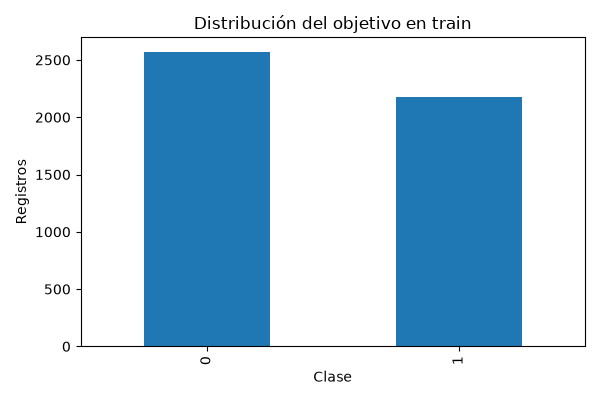

In [2]:
from activity_churn.flujo import explorar
from IPython.display import Image
display(Markdown(explorar(PROJECT_ROOT)))
display(Image(filename=str(PROJECT_ROOT / "reports/eda/distribucion_target.png")))


## Alertas de la ejecucion

Avisos agrupados con descripcion generica, acciones sugeridas y detalle original. Los errores de celda no se ocultan.

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/02_analisis_exploratorio.json")
from activity_churn.informe import generar_informe
generar_informe(PROJECT_ROOT)


WindowsPath('D:/portafolio/Analisis/churn/ActivityChurn/reports/informe_final/informe_final.md')